# 03 — Paired YOLO26n Training

Fine-tune the pretrained neck/head on matched Raw and Gamma-or-Skip S10 inputs using the same initialization, budget and Raw-development selection protocol. Native training owns optimization, checkpointing and per-epoch validation; no upstream preparation or separate baseline evaluation is invoked.

- **Inputs:** Frozen protocol/subsets/policy/decision and prepared five-class datasets, paired S10 exports, Raw development export and pinned local `yolo26n.pt`.
- **Outputs:** `runs/training-five-s10-v1/`: named native runs, native best.pt/last.pt, results.csv, args.yaml and a minimal paired dataset manifest.
- **Prerequisites:** Study environment, compatible CUDA hardware for recorded settings, prepared artifacts and a new native training root or explicit native resume.

**Outline**

1. [Configuration and Preflight](#configuration-preflight)
2. [Pretrained Initialization and Paired Inputs](#pretrained-paired-inputs)
3. [Raw Training](#raw-training)
4. [Adaptive Training](#adaptive-training)
5. [Convergence and Resource Inspection](#convergence-resources)
6. [Checkpoint and Integrity Summary](#checkpoint-integrity)

Set paths in section 1, then **Restart & Run All**. Only this phase executes.
Missing or mismatched required artifacts fail; upstream phases are never launched.
Uses five classes: car, truck, bus, motorcycle and bicycle. Historical six-class artifacts stay in their original roots.

<a id="configuration-preflight"></a>

## 1. Configuration and Preflight

Select paths and explicit native per-branch resume choices. Missing inputs fail rather than invoking data/preprocessing notebooks.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from vehicle_detection.common import read_json, require_paths, write_json
from vehicle_detection.finetuning import TRAIN_SETTINGS, prepare_pair, train_branch
from vehicle_detection.protocol import validate_protocol

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
PROTOCOL_PATH = ROOT / "runs/issue5-v1/protocol.json"
PREPARED = ROOT / "runs/preprocessing-five-v1"
SUBSETS_PATH = ROOT / "runs/issue6-v2/subsets.json"
POLICY_PATH = ROOT / "docs/issue6-v2/policy.json"
RAW_DEVELOPMENT = PREPARED / "development/raw"
CHECKPOINT = ROOT / "weights/yolo26n.pt"
TRAIN_ROOT = ROOT / "runs/training-five-s10-v1"
DECISION_PATH = ROOT / "docs/issue11-v2/v3_decision.json"
RESUME = {"raw": False, "adaptive": False}
require_paths(
    protocol=PROTOCOL_PATH,
    subsets=SUBSETS_PATH,
    policy=POLICY_PATH,
    decision=DECISION_PATH,
    training_pair=PREPARED / "datasets/S10/pair.json",
    development=RAW_DEVELOPMENT / "verified.json",
    checkpoint=CHECKPOINT,
)
protocol = validate_protocol(read_json(PROTOCOL_PATH))

<a id="pretrained-paired-inputs"></a>

## 2. Pretrained Initialization and Paired Inputs

Verify pinned pretrained semantics/architecture, verified export identities/roles, frozen recipe and equal settings. The pinned YOLO26n requires 11 backbone modules for native freeze. Pretrained inference belongs to notebook 04.

In [3]:
experiment = prepare_pair(
    protocol,
    read_json(SUBSETS_PATH),
    read_json(POLICY_PATH),
    read_json(DECISION_PATH),
    PREPARED / "datasets/S10",
    RAW_DEVELOPMENT,
    CHECKPOINT,
    TRAIN_ROOT,
)
print("Paired protocol:", experiment["protocol_id"])
print("Classes:", experiment["training"]["raw"]["export"]["conversion"]["classes"])
print("Backbone modules frozen:", experiment["freeze"])
display(pd.Series(TRAIN_SETTINGS, name="identical branch settings"))

Paired protocol: 680090b8eef098fbe10c77e632aacbfd3d6854d8489d7518e20f062e032b6e44
Classes: ['car', 'truck', 'bus', 'motorcycle', 'bicycle']
Backbone modules frozen: 11


imgsz                640
batch                 16
device                 0
conf               0.001
iou                  0.7
max_det              300
quantize              32
nms                False
agnostic_nms       False
rect               False
augment            False
seed                2026
deterministic       True
workers                8
plots               True
verbose            False
epochs                20
patience               0
amp                False
optimizer          AdamW
lr0                0.001
lrf                 0.01
cos_lr              True
warmup_epochs        3.0
warmup_bias_lr       0.0
weight_decay      0.0005
nbs                   64
cls_remap           True
cache              False
fraction             1.0
compile            False
channels_last      False
save                True
val                 True
augmentations         []
hsv_h                  0
hsv_s                  0
hsv_v                  0
degrees                0
translate              0


<a id="raw-training"></a>

## 3. Raw Training

Run or reuse the Raw branch. Existing native results are reused. To continue an interrupted run, opt in to native last.pt resume; it is not bitwise continuation.

In [4]:
completed = {"raw": train_branch(experiment, "raw", TRAIN_ROOT, resume=RESUME["raw"])}
print("Raw completion:", completed["raw"]["budget"])

Raw completion: {'epochs': 20, 'images_per_epoch': 4890}


<a id="adaptive-training"></a>

## 4. Adaptive Training

Run Gamma-or-Skip independently from the same pinned initialization and full budget. Both native histories must show the same epoch/image budget; optimizer step parity is not independently audited.

In [5]:
completed["adaptive"] = train_branch(experiment, "adaptive", TRAIN_ROOT, resume=RESUME["adaptive"])
print("Completed paired budgets:", {b: r["budget"] for b, r in completed.items()})

Completed paired budgets: {'raw': {'epochs': 20, 'images_per_epoch': 4890}, 'adaptive': {'epochs': 20, 'images_per_epoch': 4890}}


<a id="convergence-resources"></a>

## 5. Convergence and Resource Inspection

Inspect native training histories on the same Raw-development population. Loss decline alone is not detection improvement; distinguish best-epoch and final-epoch outcomes.

Native CSV time includes training and per-epoch validation; final checkpoint validation and offline preprocessing costs are separate. Original offline export timings were instrumented/resumed and are not performance evidence.

Timing sums the visible native CSV sessions. It excludes discarded partial-epoch work, setup, downtime and final best-checkpoint validation; a restart with no visible clock decrease requires the retained logs. Dotted lines mark a native timing reset. AP markers select best.pt by mAP50:95, including on the mAP50 panel.

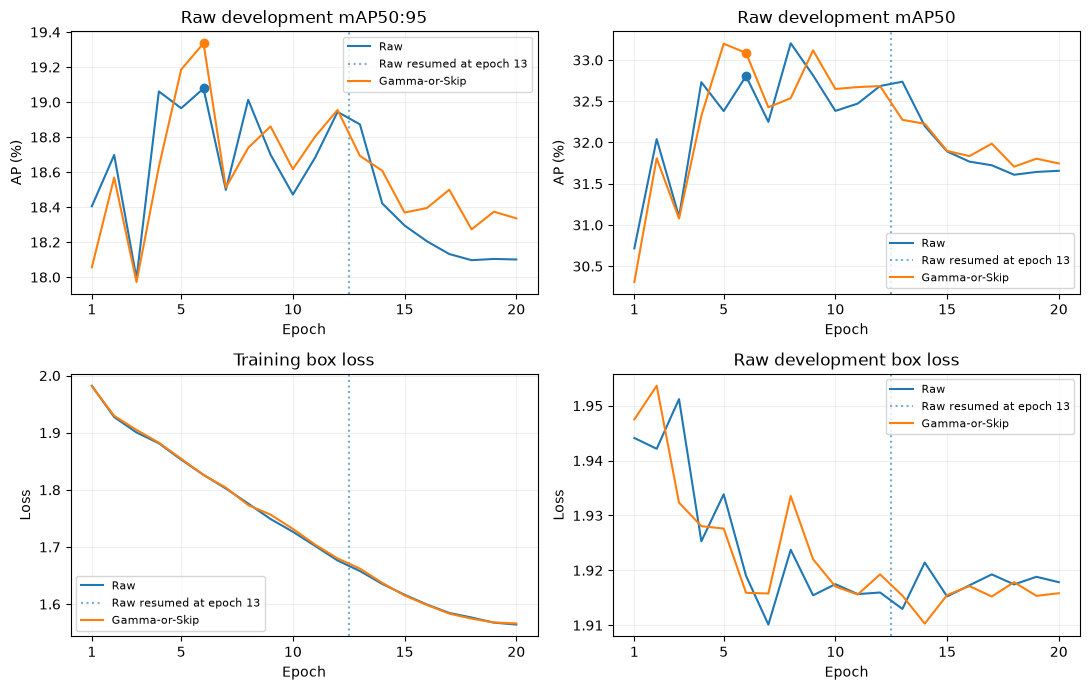

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
plots = [
    ("metrics/mAP50-95(B)", "Raw development mAP50:95", 100),
    ("metrics/mAP50(B)", "Raw development mAP50", 100),
    ("train/box_loss", "Training box loss", 1),
    ("val/box_loss", "Raw development box loss", 1),
]
for branch, label, color in [
    ("raw", "Raw", "tab:blue"),
    ("adaptive", "Gamma-or-Skip", "tab:orange"),
]:
    history = pd.read_csv(TRAIN_ROOT / branch / "results.csv")
    for ax, (metric, title, factor) in zip(axes.flat, plots, strict=True):
        ax.plot(history.epoch, history[metric] * factor, label=label, color=color)
        if factor == 100:
            best = history.loc[history.epoch == completed[branch]["best_epoch"]].iloc[0]
            ax.scatter(best.epoch, best[metric] * factor, color=color, zorder=3)
        for epoch in completed[branch]["timing_reset_epochs"]:
            ax.axvline(
                epoch - 0.5,
                color=color,
                linestyle=":",
                alpha=0.6,
                label=f"{label} resumed at epoch {epoch}",
            )
        ax.set(title=title, xlabel="Epoch", ylabel="AP (%)" if factor == 100 else "Loss")
        ax.set_xticks([1, 5, 10, 15, 20])
        ax.grid(alpha=0.2)
        ax.legend(fontsize=8)
plt.tight_layout()
fig.savefig(TRAIN_ROOT / "convergence.png", dpi=180)
plt.show()

These plots report the current named runs only. Historical S10 results remain separately attributed, and one seed does not establish a reliable preprocessing advantage.

<a id="checkpoint-integrity"></a>

## 6. Checkpoint and Integrity Summary

Inspect native checkpoint hashes and matched epoch/image budgets. Notebook 04 loads native weights directly; it never starts a trainer.

In [7]:
from vehicle_detection.common import file_hash

display(
    pd.DataFrame(
        [
            {
                "branch": branch,
                "best_epoch": receipt["best_epoch"],
                "final_epoch": receipt["final_epoch"],
                "timing_reset_epochs": receipt["timing_reset_epochs"],
                "training_validation_seconds": receipt["training_validation_seconds"],
                **receipt["budget"],
                "best_sha256": file_hash(receipt["best_checkpoint"]),
                "last_sha256": file_hash(receipt["last_checkpoint"]),
            }
            for branch, receipt in completed.items()
        ]
    )
)
write_json(TRAIN_ROOT / "summary.json", completed)
print("Final test remains locked. Native epoch-boundary resume is not bitwise continuation.")

,branch,best_epoch,final_epoch,timing_reset_epochs,training_validation_seconds,epochs,images_per_epoch,best_sha256,last_sha256
0,raw,6,20,[13],1477.653,20,4890,2d5464636781977c61e811a28285b9b8949575eec8a9ce...,797ef0b2457d90c50f2c4ba748f6f2c76af6badd4047c2...
1,adaptive,6,20,[],1439.300,20,4890,dac387f119a2fb547e107be86a2f59052ff58c75ef5c29...,f48ae4bc9f098d17e25882e6baba272ede0e8dfba0cf1a...


Final test remains locked. Native epoch-boundary resume is not bitwise continuation.
